# Reconnaissance de chiffres manuscrits : classification multiclasse

Ce notebook construit un modèle qui classe des images de chiffres manuscrits, de 0 à 9. Chaque image fait 8 × 8 pixels.

Le jeu `load_digits` est inclus dans scikit-learn.



In [3]:
import os
os.environ["OMP_NUM_THREADS"] = "2"

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
pd.set_option("display.precision", 3)

print("Environnement prêt")

Environnement prêt


## 1. Chargement et vérifications

Chaque image est un tableau de 8 × 8 valeurs, aplati ici en 64 variables. Les valeurs de pixels vont de 0 à 16.

On vérifie la forme, l'absence de valeurs manquantes, la plage des pixels et l'effectif de chaque chiffre.

In [4]:
digits = load_digits()
X = digits.data
y = digits.target

print("Forme :", X.shape, "(1797 images, 64 pixels chacune)")
print("Valeurs manquantes :", int(np.isnan(X).sum()))
print("Plage des pixels :", X.min(), "à", X.max())
print("Effectifs par chiffre :", dict(zip(range(10), np.bincount(y))))

Forme : (1797, 64) (1797 images, 64 pixels chacune)
Valeurs manquantes : 0
Plage des pixels : 0.0 à 16.0
Effectifs par chiffre : {0: np.int64(178), 1: np.int64(182), 2: np.int64(177), 3: np.int64(183), 4: np.int64(181), 5: np.int64(182), 6: np.int64(181), 7: np.int64(179), 8: np.int64(174), 9: np.int64(180)}


## 2. Visualisation des données

On affiche dix exemples, un par chiffre, pour vérifier que les étiquettes correspondent bien aux images. Une erreur à ce stade invaliderait toute la suite.

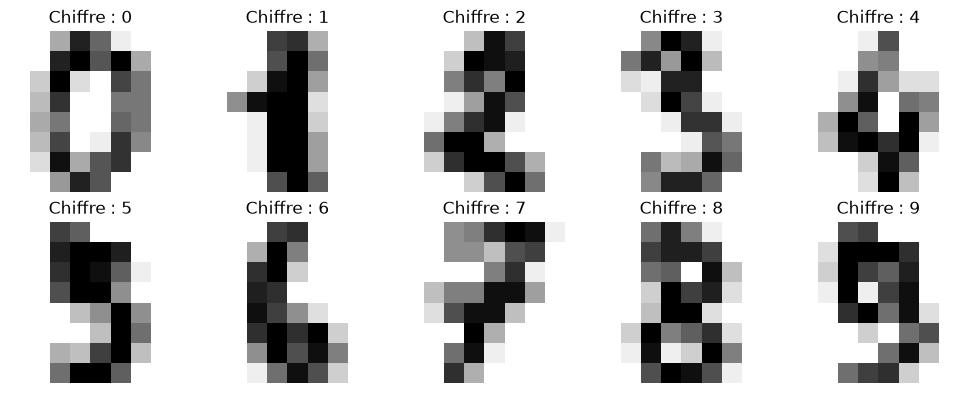

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, img, lab in zip(axes.ravel(), digits.images[:10], digits.target[:10]):
    ax.imshow(img, cmap="gray_r")
    ax.set_title(f"Chiffre : {lab}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Séparation train et test

On réserve 20 % des images pour le test. La séparation est stratifiée : chaque chiffre garde la même proportion dans les deux ensembles.

Le test ne sera utilisé qu'une seule fois, à la fin. Toutes les décisions (choix de modèle, réglages) se prennent sur le train, par validation croisée.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

print("Entraînement :", X_train.shape, "| Test :", X_test.shape)
print("Effectifs train :", np.bincount(y_train).tolist())
print("Effectifs test  :", np.bincount(y_test).tolist())

Entraînement : (1437, 64) | Test : (360, 64)
Effectifs train : [142, 146, 142, 146, 145, 145, 145, 143, 139, 144]
Effectifs test  : [36, 36, 35, 37, 36, 37, 36, 36, 35, 36]


## 4. Référence : prédire toujours la classe majoritaire

Une référence triviale donne le niveau minimal à battre. Elle prédit toujours le chiffre le plus fréquent du train.

Les dix chiffres étant presque équilibrés, cette référence doit avoisiner 10 % d'accuracy. Tout modèle sérieux doit largement la dépasser.

In [8]:
reference = DummyClassifier(strategy="most_frequent")
reference.fit(X_train, y_train)
pred_ref = reference.predict(X_test)

print("Classe prédite par la référence :", reference.predict(X_test[:1])[0])
print(f"Accuracy de la référence (test) : {accuracy_score(y_test, pred_ref):.3f}")
print(f"F1 macro de la référence (test) : {f1_score(y_test, pred_ref, average='macro'):.3f}")

Classe prédite par la référence : 1
Accuracy de la référence (test) : 0.100
F1 macro de la référence (test) : 0.018


## 5. Comparaison de modèles par validation croisée

On compare quatre familles de modèles, sur le train seulement :

- **Régression logistique** : modèle linéaire, sert de premier point de comparaison.
- **K plus proches voisins** : décide selon les images les plus proches.
- **SVM à noyau RBF** : cherche une frontière non linéaire entre les classes.
- **Forêt aléatoire** : combine de nombreux arbres, sans besoin de standardisation.

Le prétraitement (standardisation) est placé dans chaque pipeline, pour qu'il soit recalculé à chaque pli : aucune information de validation ne fuit dans l'entraînement.

Deux mesures : l'accuracy, et le F1 macro, qui pénalise les modèles qui ignorent une classe.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ["accuracy", "f1_macro"]

modeles = {
    "Régression logistique": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    "K plus proches voisins": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "SVM (noyau RBF)": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0)),
    "Forêt aléatoire": RandomForestClassifier(n_estimators=200, random_state=SEED),
}

lignes = []
for nom, modele in modeles.items():
    scores = cross_validate(modele, X_train, y_train, cv=cv, scoring=scoring)
    lignes.append({
        "Modèle": nom,
        "Accuracy (moyenne)": scores["test_accuracy"].mean(),
        "Accuracy (écart-type)": scores["test_accuracy"].std(),
        "F1 macro (moyenne)": scores["test_f1_macro"].mean(),
    })

tableau_comparaison = (
    pd.DataFrame(lignes)
    .set_index("Modèle")
    .sort_values("Accuracy (moyenne)", ascending=False)
    .round(3)
)
tableau_comparaison

,Accuracy (moyenne),Accuracy (écart-type),F1 macro (moyenne)
Modèle,,,
SVM (noyau RBF),0.981,0.006,0.981
Forêt aléatoire,0.976,0.010,0.976
K plus proches voisins,0.976,0.010,0.976
Régression logistique,0.968,0.007,0.968


## 6. Réglage du SVM

Le SVM dépend de deux hyperparamètres :

- **C** : contrôle le compromis entre marge large et erreurs tolérées. Petit C : frontière lisse, risque de sous-apprentissage. Grand C : frontière plus adaptée au train, risque de surapprentissage.
- **gamma** : contrôle la portée de l'influence de chaque exemple. Petit gamma : frontière douce. Grand gamma : frontière qui épouse les détails.

La recherche se fait par validation croisée sur le train. Le test n'est pas utilisé.

In [10]:
pipeline_svm = make_pipeline(StandardScaler(), SVC(kernel="rbf"))
grille = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": ["scale", 0.001, 0.01, 0.1],
}

recherche = GridSearchCV(pipeline_svm, grille, cv=cv, scoring="accuracy", n_jobs=1)
recherche.fit(X_train, y_train)

print("Meilleurs paramètres :", recherche.best_params_)
print(f"Accuracy de validation croisée : {recherche.best_score_:.4f}")

resultats = pd.DataFrame(recherche.cv_results_)[
    ["param_svc__C", "param_svc__gamma", "mean_test_score", "std_test_score"]
]
resultats.columns = ["C", "gamma", "Accuracy moyenne", "Écart-type"]
resultats.sort_values("Accuracy moyenne", ascending=False).head(8).round(4)

Meilleurs paramètres : {'svc__C': 1, 'svc__gamma': 'scale'}
Accuracy de validation croisée : 0.9812


,C,gamma,Accuracy moyenne,Écart-type
4,1.0,scale,0.981,0.006
8,10.0,scale,0.980,0.006
12,100.0,scale,0.980,0.006
14,100.0,0.01,0.979,0.005
10,10.0,0.01,0.979,0.005
6,1.0,0.01,0.978,0.008
13,100.0,0.001,0.976,0.005
9,10.0,0.001,0.976,0.013


## 7. Test final

C'est la seule évaluation sur le jeu de test. Le modèle retenu est celui que la recherche a entraîné sur tout le train, avec les meilleurs paramètres (C = 1, gamma = `scale`).

On mesure l'accuracy et le F1 macro, puis le rapport de classification par chiffre, et la matrice de confusion 10 × 10.

Cette cellule ne doit être exécutée qu'une fois. Si le notebook est relancé, repartez du début.

Accuracy (test) : 0.975
F1 macro (test) : 0.975

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        36
           1      0.946     0.972     0.959        36
           2      1.000     1.000     1.000        35
           3      1.000     1.000     1.000        37
           4      0.946     0.972     0.959        36
           5      0.974     1.000     0.987        37
           6      0.973     1.000     0.986        36
           7      0.921     0.972     0.946        36
           8      1.000     0.914     0.955        35
           9      1.000     0.917     0.957        36

    accuracy                          0.975       360
   macro avg      0.976     0.975     0.975       360
weighted avg      0.976     0.975     0.975       360



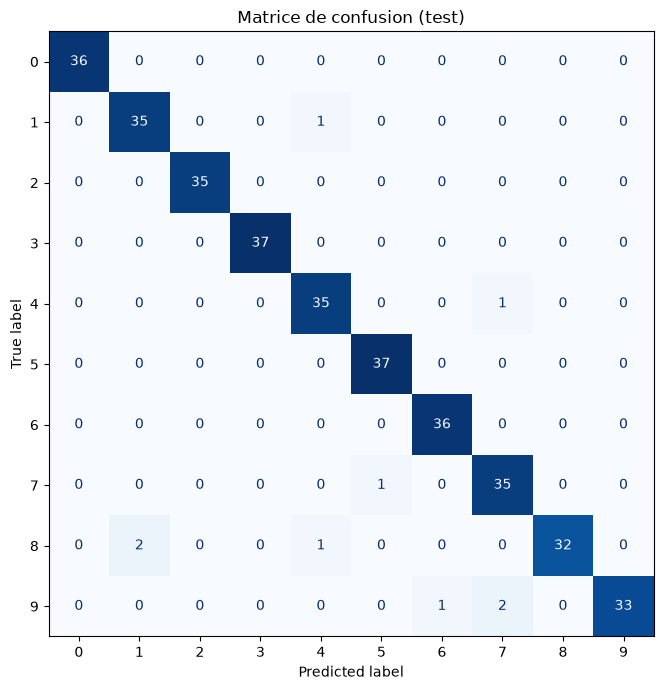

In [11]:
from sklearn.metrics import classification_report

modele_final = recherche.best_estimator_
pred_test = modele_final.predict(X_test)

print(f"Accuracy (test) : {accuracy_score(y_test, pred_test):.3f}")
print(f"F1 macro (test) : {f1_score(y_test, pred_test, average='macro'):.3f}")
print()
print(classification_report(y_test, pred_test, digits=3))

cm = confusion_matrix(y_test, pred_test)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Matrice de confusion (test)")
plt.tight_layout()
plt.show()

## 8. Analyse des erreurs

On identifie les paires de chiffres les plus souvent confondues, puis on affiche les images mal classées. Cette analyse est descriptive : elle sert à comprendre les erreurs, pas à modifier le modèle.

Erreurs : 9 sur 360 (2.5%)

Confusions les plus fréquentes (vrai → prédit) :
  8 → 1 : 2 cas
  9 → 7 : 2 cas
  4 → 7 : 1 cas
  9 → 6 : 1 cas
  7 → 5 : 1 cas
  1 → 4 : 1 cas
  8 → 4 : 1 cas


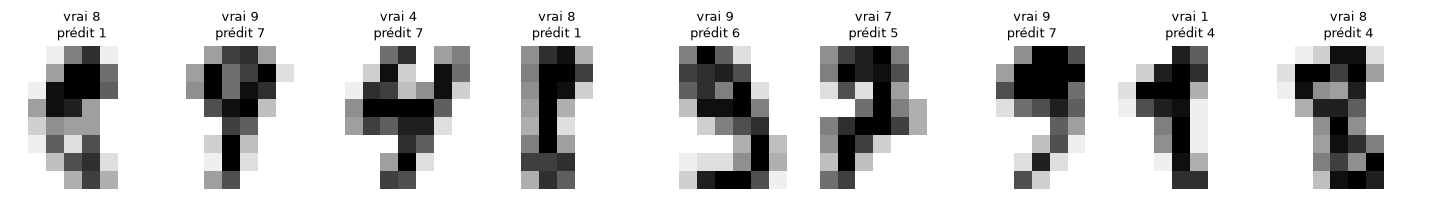

In [12]:
idx_train, idx_test = train_test_split(
    np.arange(len(y)), test_size=0.20, stratify=y, random_state=SEED
)
assert np.array_equal(X[idx_test], X_test), "La séparation ne correspond pas"

erreurs = np.where(pred_test != y_test)[0]
print(f"Erreurs : {len(erreurs)} sur {len(y_test)} ({len(erreurs) / len(y_test):.1%})")

paires = pd.Series([(int(y_test[i]), int(pred_test[i])) for i in erreurs]).value_counts()
print("\nConfusions les plus fréquentes (vrai → prédit) :")
for (vrai, predit), n in paires.items():
    print(f"  {vrai} → {predit} : {n} cas")

fig, axes = plt.subplots(1, len(erreurs), figsize=(1.6 * len(erreurs), 2.2))
for ax, i in zip(np.atleast_1d(axes), erreurs):
    ax.imshow(digits.images[idx_test[i]], cmap="gray_r")
    ax.set_title(f"vrai {y_test[i]}\nprédit {pred_test[i]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 9. Conclusion

### Résultats

- **Référence** (classe majoritaire) : accuracy de 0,100, soit le hasard pour dix classes presque équilibrées.
- **Choix du modèle** : le SVM à noyau RBF obtient la meilleure accuracy en validation croisée (0,981), devant la forêt aléatoire et les K plus proches voisins (0,976), puis la régression logistique (0,968).
- **Réglage** : `C = 1` et `gamma = "scale"`. Le réglage apporte peu : les huit meilleures combinaisons sont comprises entre 0,976 et 0,981.
- **Test final** : accuracy de 0,975 et F1 macro de 0,975, sur 360 images jamais utilisées pour le choix du modèle. Le résultat est cohérent avec la validation.
- **Erreurs** : 9 sur 360, dispersées sur plusieurs paires de chiffres, avec 8 → 1 et 9 → 7 en tête.



In [13]:
resume = pd.DataFrame({
    "Étape": [
        "Référence (classe majoritaire, test)",
        "Meilleur modèle en validation (SVM, C = 1)",
        "Test final (SVM, C = 1)",
    ],
    "Accuracy": [
        accuracy_score(y_test, pred_ref),
        recherche.best_score_,
        accuracy_score(y_test, pred_test),
    ],
    "F1 macro": [
        f1_score(y_test, pred_ref, average="macro"),
        np.nan,
        f1_score(y_test, pred_test, average="macro"),
    ],
})
resume.set_index("Étape").round(3)

,Accuracy,F1 macro
Étape,,
"Référence (classe majoritaire, test)",0.100,0.018
"Meilleur modèle en validation (SVM, C = 1)",0.981,NaN
"Test final (SVM, C = 1)",0.975,0.975
